Loading data from /kyb/agpd/wwang/sst-pomdp/outputs...
Data Loaded. Valid Subjects: 5918
Running PCA and Clustering (k=4)...
Generating PCA Parameter Plots...


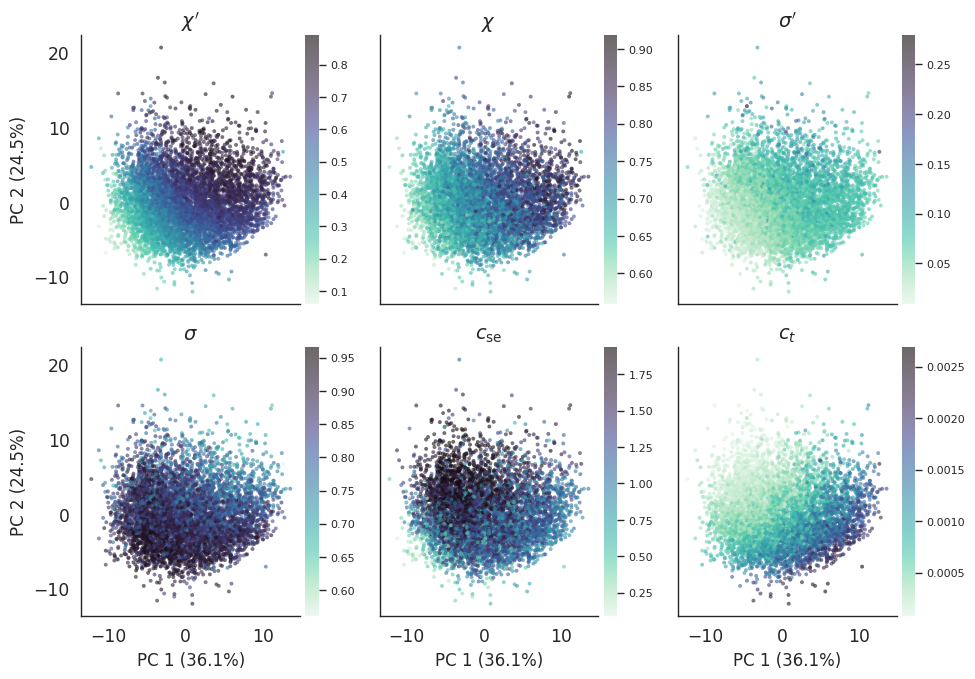

Generating PCA Cluster & ADHD Plot...


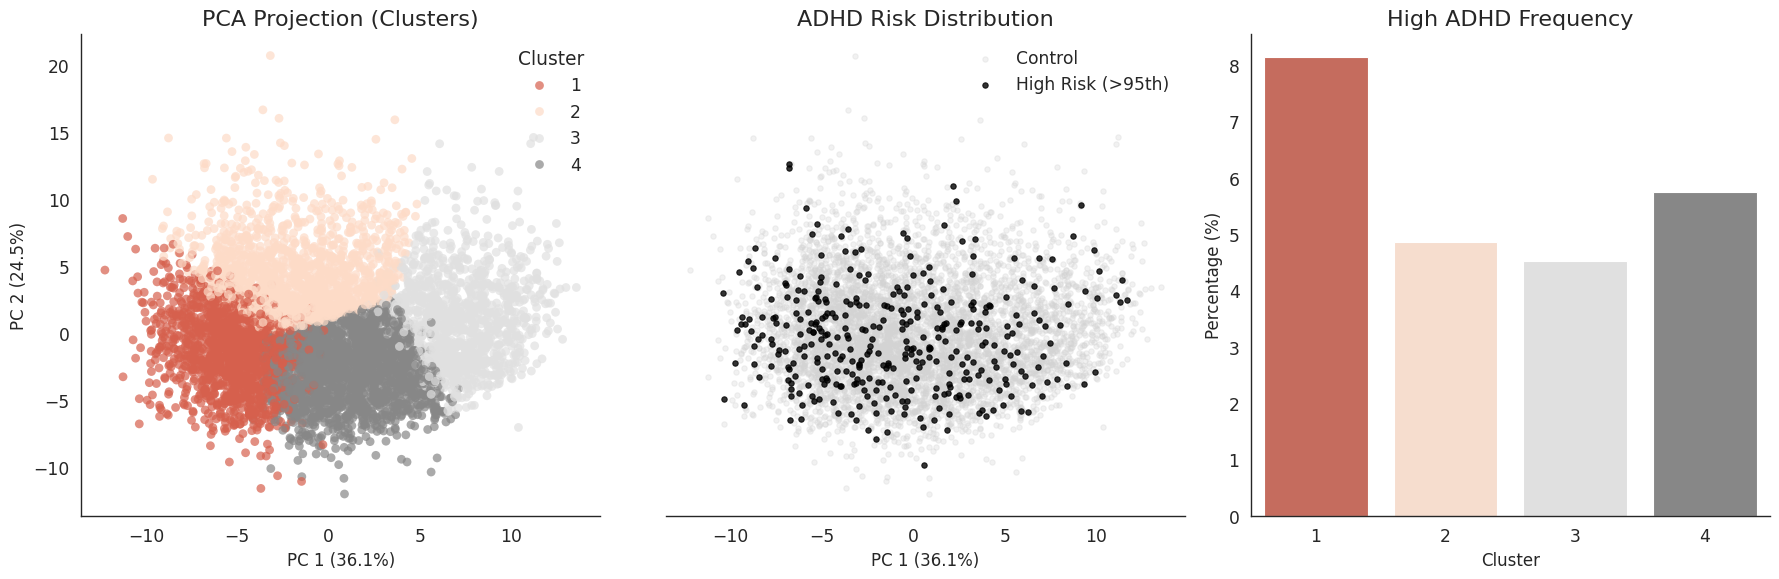

Generating Plot 3: Cluster Parameter Spread (Box + Point)...


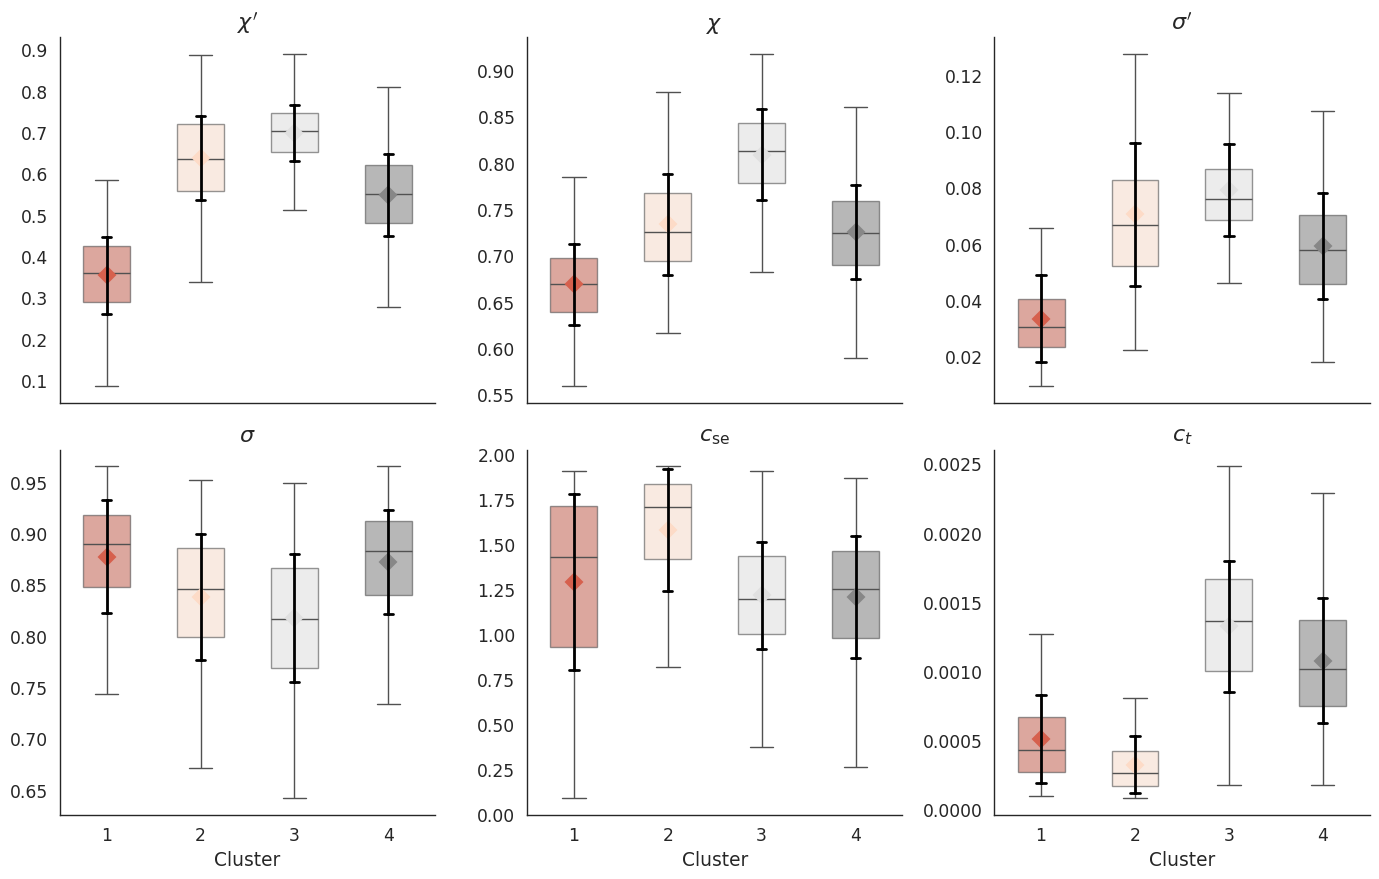

Calculating ADHD Stats...
High ADHD defined as > 8.00
         High ADHD Freq (%)
cluster                    
1                  8.156271
2                  4.869186
3                  4.532840
4                  5.744256
Analysis Complete.


In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from math import pi
from pathlib import Path

# ==========================================
# 0. Path Definitions & Style
# ==========================================
BASE_DIR = Path('/kyb/agpd/wwang/data/')
OUT_DIR = Path('/kyb/agpd/wwang/sst-pomdp/outputs/')

# Journal Style Settings
sns.set_context("paper", font_scale=1.4)
sns.set_style("white") # Clean background (no grid)
PALETTE = sns.color_palette("RdGy", 4)

# Cutoff for the ADHD visualization (e.g., top 25%)
PERCENTILE_CUTOFF = 95 

# LaTeX Display Names for Plots
PARAM_DISPLAY_NAMES = {
    'q_d_n': r"$\chi'$",
    'q_d': r"$\chi$",
    'q_s_n': r"$\sigma'$",
    'q_s': r"$\sigma$",
    'cost_stop_error': r"$c_{\mathrm{se}}$",
    'cost_time': r"$c_t$",
}

# ==========================================
# 1. Data Loading & Filtering
# ==========================================
def load_and_filter_data():
    print(f"Loading data from {OUT_DIR}...")
    
    df_emb = pd.read_csv(OUT_DIR / 'embeddings.csv')
    df_stats = pd.read_csv(OUT_DIR / 'stats_beh_full.csv')
    df_post = pd.read_csv(OUT_DIR / 'posterior_summary.csv')

    df_emb['year'] = df_emb['year'].astype(str)
    df_stats['year'] = df_stats['year'].astype(str)
    df_post['subject_year'] = df_post['subject_year'].astype(str)

    df_post_pivot = df_post.pivot_table(index=['subject_id', 'subject_year'], 
                                        columns='param', 
                                        values='mean').reset_index()
    df_post_pivot.rename(columns={'subject_year': 'year'}, inplace=True)

    df_merged_1 = pd.merge(df_emb, df_stats, on=['subject_id', 'year', 'filename'], how='inner')
    df_final = pd.merge(df_merged_1, df_post_pivot, on=['subject_id', 'year'], how='inner')
    
    print(f"Data Loaded. Valid Subjects: {len(df_final)}")
    return df_final

# ==========================================
# 2. Clustering & PCA
# ==========================================
def run_pca_and_clustering(df, k=4):
    print(f"Running PCA and Clustering (k={k})...")
    
    embedding_cols = [f'emb_{i}' for i in range(64)]
    X = df[embedding_cols].values

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Run PCA
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(X_scaled)
    df['pca_1'] = pca_result[:, 0]
    df['pca_2'] = pca_result[:, 1]
    
    # Run K-Means
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    df['cluster'] = kmeans.fit_predict(X_scaled) + 1
    
    return df, pca

# ==========================================
# 3. Visualization: PCA Parameters (Plot 1)
# ==========================================
def plot_pca_param(df, pca_model):
    print("Generating PCA Parameter Plots...")

    params = ['q_d_n', 'q_d', 'q_s_n', 'q_s', 'cost_stop_error', 'cost_time']
    
    # Calculate Variance Ratios
    var_ratios = pca_model.explained_variance_ratio_ * 100
    pc1_label = f"PC 1 ({var_ratios[0]:.1f}%)"
    pc2_label = f"PC 2 ({var_ratios[1]:.1f}%)"
    
    # Share axes to reduce chaos
    fig, axes = plt.subplots(2, 3, figsize=(10, 7), sharex=True, sharey=True)
    axes = axes.flatten()

    for i, param in enumerate(params):
        if param in df.columns:
            # Scatter with gradient color
            sc = axes[i].scatter(df['pca_1'], df['pca_2'], c=df[param], cmap='mako_r', alpha=0.6, s=8, linewidth=0)
            
            # Use LaTeX Title
            title = PARAM_DISPLAY_NAMES.get(param, param)
            axes[i].set_title(title, fontsize=14)
            
            # Set labels only on outer plots (bottom row and left column)
            if i >= 3: 
                axes[i].set_xlabel(pc1_label, fontsize=12)
            if i % 3 == 0:
                axes[i].set_ylabel(pc2_label, fontsize=12)
            
            # Clean Aesthetics
            sns.despine(ax=axes[i], trim=False)
            
            # Custom Colorbar
            cbar = plt.colorbar(sc, ax=axes[i], pad=0.02)
            cbar.ax.tick_params(labelsize=8)
            cbar.outline.set_visible(False)
        else:
            axes[i].axis('off')
            
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'embed_param.png', dpi=300)
    plt.show()

# ==========================================
# 4. Visualization: PCA Clusters & ADHD (Plot 2)
# ==========================================
def plot_pca_cluster_and_adhd(df, pca_model):
    print("Generating PCA Cluster & ADHD Plot...")
    
    # Calculate Variance Ratios
    var_ratios = pca_model.explained_variance_ratio_ * 100
    pc1_label = f"PC 1 ({var_ratios[0]:.1f}%)"
    pc2_label = f"PC 2 ({var_ratios[1]:.1f}%)"
    
    # Define Threshold
    adhd_threshold = np.percentile(df['adhd'].dropna(), PERCENTILE_CUTOFF)
    
    # Create 1x3 Subplots (Increased width to 18)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # --- Subplot 1: PCA Clusters ---
    sns.scatterplot(data=df, x='pca_1', y='pca_2', hue='cluster', 
                    palette=PALETTE, alpha=0.7, s=40, legend='full', 
                    linewidth=0, ax=axes[0])
    
    axes[0].set_title('PCA Projection (Clusters)', fontsize=16)
    axes[0].set_xlabel(pc1_label, fontsize=12)
    axes[0].set_ylabel(pc2_label, fontsize=12)
    axes[0].legend(title='Cluster', loc='upper right', frameon=False)
    sns.despine(ax=axes[0])

    # --- Subplot 2: ADHD Thresholding ---
    high_risk = df[df['adhd'] >= adhd_threshold]
    control = df[df['adhd'] < adhd_threshold]
    
    # 1. Plot Control (Grey Background)
    axes[1].scatter(control['pca_1'], control['pca_2'], c='lightgrey', 
                    s=15, alpha=0.3, label='Control')
    # 2. Plot High Risk (Red Foreground)
    axes[1].scatter(high_risk['pca_1'], high_risk['pca_2'], c='k', 
                    s=15, alpha=0.8, label=f'High Risk (>{PERCENTILE_CUTOFF}th)')
    
    axes[1].set_title(f'ADHD Risk Distribution', fontsize=16)
    axes[1].set_xlabel(pc1_label, fontsize=12)
    axes[1].set_yticks([]) # Optional: Remove Y ticks since they are shared/meaningless here
    axes[1].set_ylabel("")
    axes[1].legend(loc='upper right', frameon=False)
    sns.despine(ax=axes[1], left=True) # Clean look

    # --- Subplot 3: High ADHD Frequency per Cluster ---
    # Calculate % High ADHD for each cluster
    df_temp = df.copy()
    df_temp['is_high_risk'] = df_temp['adhd'] >= adhd_threshold
    
    # Group by cluster and calculate mean (proportion), then multiply by 100
    cluster_stats = df_temp.groupby('cluster')['is_high_risk'].mean().reset_index()
    cluster_stats['is_high_risk'] *= 100
    
    sns.barplot(
        data=cluster_stats, 
        x='cluster', 
        y='is_high_risk', 
        hue='cluster',     # Mapped for color consistency
        palette=PALETTE, 
        legend=False,      # Hide legend
        ax=axes[2]
    )
    
    axes[2].set_title('High ADHD Frequency', fontsize=16)
    axes[2].set_ylabel('Percentage (%)', fontsize=12)
    axes[2].set_xlabel('Cluster', fontsize=12)
    # axes[2].set_ylim(0, 100) # Fix scale 0-100%
    sns.despine(ax=axes[2])
    
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'embed_cluster_adhd.png', dpi=300)
    plt.show()

# ==========================================
# 5. Visualization: Parameter Spread (Box + Point)
# ==========================================
def plot_cluster_parameter_errorbars(df):
    print("Generating Plot 3: Cluster Parameter Spread (Box + Point)...")
    features_cognitive = ['q_d_n', 'q_d', 'q_s_n', 'q_s', 'cost_stop_error', 'cost_time']
    
    fig, axes = plt.subplots(2, 3, figsize=(14, 9), sharex=True)
    axes = axes.flatten()
    
    for i, param in enumerate(features_cognitive):
        if param in df.columns:
            # 1. BOX PLOT: Shows Median & IQR
            sns.boxplot(
                data=df,
                x='cluster',
                y=param,
                hue='cluster',      # Fixes palette warning
                palette=PALETTE,
                legend=False,
                showfliers=False,   # Hide outliers to keep it clean (focus on distribution shape)
                width=0.5,          # Thinner boxes to leave room
                boxprops={'alpha': 0.6}, # Slight transparency
                ax=axes[i],
                zorder=0
            )

            # 2. POINT PLOT: Shows Mean + SD (The "Center" & "Variation")
            sns.pointplot(
                data=df, 
                x='cluster', 
                y=param, 
                hue='cluster',
                palette=PALETTE,
                legend=False,
                ax=axes[i],
                linestyle='none', 
                capsize=0.1, 
                markers='D',      # Diamond shape for Mean
                markersize=8,     
                linewidth=2,      
                errorbar='sd',    # Standard Deviation
                zorder=10,
                err_kws={'color': 'black', 'linewidth': 2} # Black error bars for contrast
            )
            
            # Formatting
            title = PARAM_DISPLAY_NAMES.get(param, param)
            axes[i].set_title(title, fontsize=16)
            axes[i].set_ylabel("") 
            axes[i].set_xlabel("Cluster" if i >= 3 else "")
            
            sns.despine(ax=axes[i])
        else:
            axes[i].axis('off')
            
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'embed_params_boxplot.png', dpi=300)
    plt.show()

# ==========================================
# 6. Visualization: ADHD Stats (Plot 4 - Text)
# ==========================================
def analyze_adhd_stats(df):
    print("Calculating ADHD Stats...")
    # Matches the percentile logic used in Plot 2
    threshold = np.percentile(df['adhd'].dropna(), PERCENTILE_CUTOFF)
    df['high_adhd'] = df['adhd'] >= threshold
    
    summary = df.groupby('cluster').agg({
        'high_adhd': lambda x: np.mean(x) * 100
    }).rename(columns={'high_adhd': 'High ADHD Freq (%)'})
    
    print(f"High ADHD defined as > {threshold:.2f}")
    print(summary)

# ==========================================
# MAIN EXECUTION
# ==========================================
if __name__ == "__main__":
    # 1. Load
    df = load_and_filter_data()
    
    # 2. Run PCA & Clustering
    df, pca_model = run_pca_and_clustering(df, k=4)
    
    # 3. Plot
    plot_pca_param(df, pca_model)
    
    # Modified Plot 2 (Cluster + ADHD side-by-side)
    plot_pca_cluster_and_adhd(df, pca_model)
    
    # Modified Plot 3 (Dot + Error Bars instead of Radar)
    plot_cluster_parameter_errorbars(df)
    
    analyze_adhd_stats(df)



    print("Analysis Complete.")